# Getting Audio Data

In [7]:
import librosa
from IPython.display import Audio

audio, sr = librosa.load("sample_Data/Czesc3.wav", sr=16000, mono=True, duration=17)

# Play the audio file used in the recognition
Audio(audio, rate=sr)

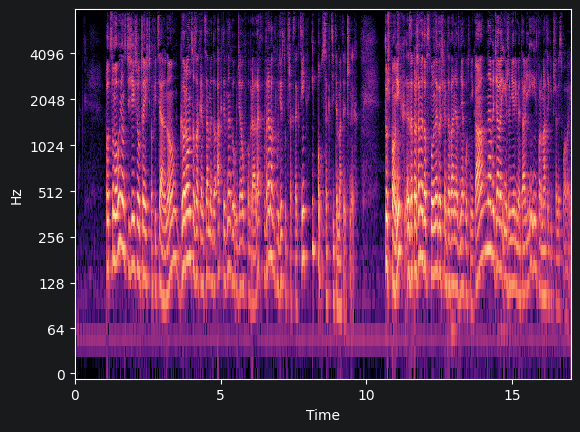

In [8]:
import numpy as np
import matplotlib.pyplot as plt

S = np.abs(librosa.stft(audio, n_fft=1024, hop_length=256))
librosa.display.specshow(librosa.amplitude_to_db(S, ref=np.max), sr=sr, hop_length=256, x_axis='time', y_axis='log')
plt.show()

# Nemo Model

In [4]:
import nemo.collections.asr as nemo_asr
import warnings

warnings.filterwarnings("ignore")

# Load the Polish-specific model
asr_model = nemo_asr.models.EncDecHybridRNNTCTCBPEModel.from_pretrained(
    model_name="nvidia/stt_pl_fastconformer_hybrid_large_pc"
)




[NeMo I 2026-05-09 19:15:07 mixins:184] Tokenizer SentencePieceTokenizer initialized with 1024 tokens


[NeMo W 2026-05-09 19:15:08 modelPT:188] If you intend to do training or fine-tuning, please call the ModelPT.setup_training_data() method and provide a valid configuration file to setup the train data loader.
    Train config : 
    manifest_filepath:
    - /datasets/pl_asr_dataset/mcv-train.json
    - /datasets/pl_asr_dataset/mls-train.json
    - /datasets/pl_asr_dataset/voxpopuli-train.json
    sample_rate: 16000
    batch_size: 64
    shuffle: true
    num_workers: 8
    pin_memory: true
    use_start_end_token: false
    trim_silence: false
    max_duration: 20
    min_duration: 0.1
    is_tarred: false
    tarred_audio_filepaths: null
    shuffle_n: 2048
    bucketing_strategy: synced_randomized
    bucketing_batch_size: null
    
[NeMo W 2026-05-09 19:15:08 modelPT:195] If you intend to do validation, please call the ModelPT.setup_validation_data() or ModelPT.setup_multiple_validation_data() method and provide a valid configuration file to setup the validation data loader(s). 
 

[NeMo I 2026-05-09 19:15:09 rnnt_models:226] Using RNNT Loss : warprnnt_numba
    Loss warprnnt_numba_kwargs: {'fastemit_lambda': 0.0, 'clamp': -1.0}
[NeMo I 2026-05-09 19:15:09 rnnt_models:226] Using RNNT Loss : warprnnt_numba
    Loss warprnnt_numba_kwargs: {'fastemit_lambda': 0.0, 'clamp': -1.0}
[NeMo I 2026-05-09 19:15:09 rnnt_models:226] Using RNNT Loss : warprnnt_numba
    Loss warprnnt_numba_kwargs: {'fastemit_lambda': 0.0, 'clamp': -1.0}
[NeMo I 2026-05-09 19:15:10 save_restore_connector:285] Model EncDecHybridRNNTCTCBPEModel was successfully restored from /home/franio/.cache/huggingface/hub/models--nvidia--stt_pl_fastconformer_hybrid_large_pc/snapshots/90fc78a3d35d7140255f95d4c71cc5593f2d0c4e/stt_pl_fastconformer_hybrid_large_pc.nemo.


In [9]:
transcriptions = asr_model.transcribe(audio)
print(transcriptions[0].text)

Transcribing: 100%|██████████| 1/1 [00:01<00:00,  1.99s/it]

Podsumowując dzisiejszą część oficjalną, gorąco zachęcamy do aktywnego udziału w obradach w ramach dwudziestu trzech sekcji i posekcji tematycznych. Tuż po nich zapraszamy do wspólnego świętowania dnia hutnika na wydziale inżynierii metali i informatyki przemysłowej.


In [ ]:
# TODO: Prepare Transcription for nemo model
# TODO: What metrics should be used and diction score funtion?